<a href="https://colab.research.google.com/github/suspoz/ProyectoFinal/blob/main/Aseguradora_PrediccionCostosMedicos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#Importamos las "herramientas" o librerías que necesitamos.

import os #permite interactuar con el sistema operativo (crear carpetas, buscar rutas de archivos).
import joblib #irve para guardar (serializar) nuestro modelo entrenado en un archivo y usarlo después sin tener que reentrenarlo.
import matplotlib.pyplot as plt #sirve para crear gráficos.
import numpy as np #ayuda a hacer operaciones matemáticas avanzadas.
import pandas as pd #nos sirve para manipular tablas de datos (como un Excel).
import seaborn as sns #sirve para crear gráficos.
import gradio as gr #sirve para crear la interfaz gráfica

#sklearn (Scikit-learn) es la librería principal de Machine Learning en Python.
#De aquí sacamos los modelos, las métricas de evaluación y las herramientas para preparar los datos.
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [6]:
# Definimos la ruta directamente al archivo CSV que se encuentra en Google Colab
DATA_PATH = '/content/saludmas_seguros_proyecto2.csv'

# Leemos el archivo CSV usando pandas
df = pd.read_csv(DATA_PATH, sep=';')

# --- LIMPIEZA DE DATOS AL PRINCIPIO ---
# 1. Imputamos los valores faltantes en 'imc' usando la mediana
median_imc = df['imc'].median()
df['imc'] = df['imc'].fillna(median_imc)

# 2. Imputamos los valores faltantes en 'fumador' usando la moda (el valor más frecuente)
mode_fumador = df['fumador'].mode()[0]
df['fumador'] = df['fumador'].fillna(mode_fumador)

print("[INFO] ¡Limpieza realizada con éxito! Valores nulos eliminados al inicio del flujo.")

[INFO] ¡Limpieza realizada con éxito! Valores nulos eliminados al inicio del flujo.


In [7]:
#mprimimos en la pantalla las primeras 5 filas del archivo para ver qué aspecto tiene
print("--- Primeras filas del Dataset ---")
print(df.head())
print("\n--- Información general del Dataset ---")
#resumen para confirmar cuántas columnas hay y si falta algún dato.
print(df.info())

--- Primeras filas del Dataset ---
   edad       sexo   imc  hijos region fumador  costo_medico_anual
0    49  masculino  34.9      0   este      no            15103.13
1    29   femenino  30.0      0  oeste      no             8677.17
2    29  masculino  35.4      0  oeste      no            12888.44
3    58   femenino  34.9      0  oeste      si            38785.20
4    22  masculino  28.1      0    sur      no             3881.73

--- Información general del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   edad                1200 non-null   int64  
 1   sexo                1200 non-null   object 
 2   imc                 1200 non-null   float64
 3   hijos               1200 non-null   int64  
 4   region              1200 non-null   object 
 5   fumador             1200 non-null   object 
 6   costo_medico_anual 

In [9]:
# Creamos una carpeta llamada models (si no existe todavía) para guardar
# nuestros gráficos y el modelo entrenado.
os.makedirs("./models", exist_ok=True)

In [10]:
#Creamos y guardamos un gráfico de barras (histograma) para ver cómo se comportan los costos médicos
# (si la mayoría paga poco, cuánto pagan los que más gastan, etc.) y
# guardamos la imagen en la carpeta models
# Genera un histograma que ermite observar cómo se distribuyen los costos
# médicos anuales de los pacientes en el dataset
plt.figure(figsize=(8, 6))
#Añade títulos y etiquetas descriptivas a los ejes del gráfico
sns.histplot(df["costo_medico_anual"], kde=True, color="teal")
plt.title("Distribución del Costo Médico Anual")
plt.xlabel("Costo Médico Anual ($)")
plt.ylabel("Frecuencia")
#Guarda el gráfico: Lo almacena de forma local como una imagen
#dentro de la carpeta /content/models
plt.savefig("./models/distribucion_costos.png")
#Limpia la memoriapara evitar consumir recursos innecesarios
plt.close()

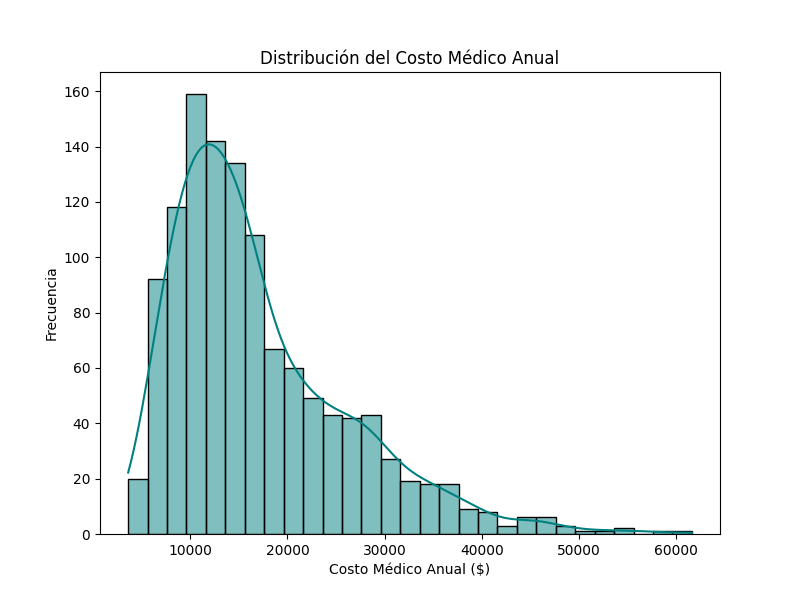

In [11]:
from IPython.display import Image

# Mostramos la imagen guardada directamente en el notebook
Image(filename='./models/distribucion_costos.png')

In [12]:
# Mapa de calor (heatmap) para ver qué variables numéricas están relacionadas
# entre sí (por ejemplo, si a mayor edad, mayor costo médico).
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de Correlación - Variables Numéricas")
plt.savefig("./models/matriz_correlacion.png")
plt.close()

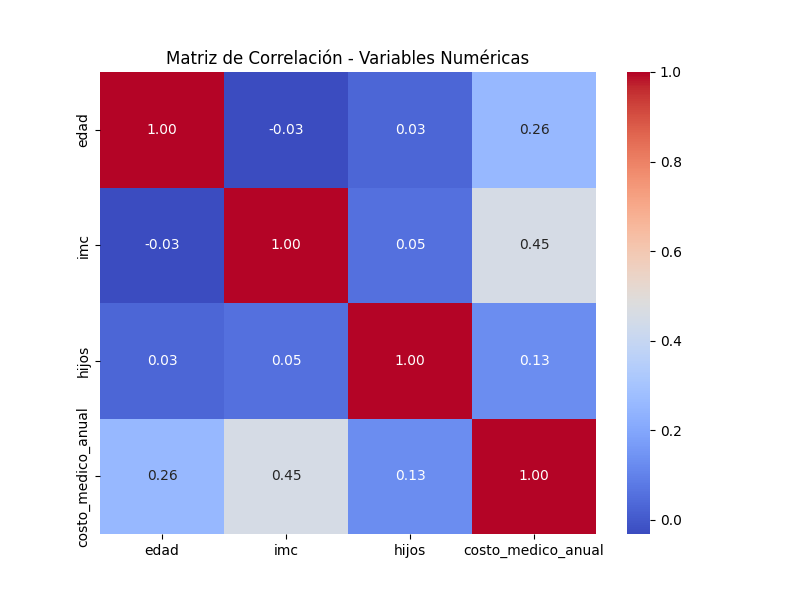

In [13]:
from IPython.display import Image

# Mostramos la imagen guardada directamente en el notebook
Image(filename='./models/matriz_correlacion.png')

In [14]:
#Separamos los datos
#Características que usaremos para predecir (edad, sexo, IMC,
# hijos, región, fumador)
X = df.drop(columns=["costo_medico_anual"])

#La variable objetivo o lo que queremos adivinar (el costo médico anual)
y = df["costo_medico_anual"]

In [16]:
#Dividimos nuestros datos en dos grupos:
# 80% para entrenar al modelo (_train) y un
#20% para examinarlo/probarlo
# random_state=42 asegura que esta división sea exactamente
#la misma cada vez que ejecutemos el código.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
#Una vez que tenemos la información preparamos los datos para que lo entienda
#la máquina
cat_cols = ["sexo", "region", "fumador"] #columnas de texto
num_cols = ["edad", "imc", "hijos"] #columnas numéricas

preprocessor = ColumnTransformer(
    transformers=[
#Las columnas numéricas (num_cols) se estandarizan con StandardScaler
#(para que todas tengan una escala similar)
        ("num", StandardScaler(), num_cols),

# Las columnas de texto (cat_cols) se transforman en números usando
# OneHotEncoder (porque las computadoras no entienden palabras como "sí" o
# "no", sino ceros y unos)
        ("cat", OneHotEncoder(drop="first"), cat_cols),
    ]
)

In [18]:
# modelo de prueba usando Regresión Lineal
lr_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("model", LinearRegression())]
)

# Lo entrenamos (fit) con los datos de entrenamiento (ahora limpios desde el inicio)
lr_pipeline.fit(X_train, y_train)

# Hacemos predicciones (predict) con los datos de prueba
y_pred_lr = lr_pipeline.predict(X_test)

In [19]:
# Medimos el modelo de Regresión Lineal usando tres métricas:
#MAE (Error Absoluto Medio): En promedio, por cuántos euros se equivoca el modelo.
#RMSE (Raíz del Error Cuadrático Medio): Penaliza los errores grandes.
#R² (Coeficiente de Determinación): Qué tan bien se ajusta el modelo a los datos (lo ideal es que esté cerca de 1.0).
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\n--- Resultados Regresión Lineal ---")
print(f"MAE: {mae_lr:.2f}")
print(f"RMSE: {rmse_lr:.2f}")
print(f"R²: {r2_lr:.4f}")


--- Resultados Regresión Lineal ---
MAE: 2653.93
RMSE: 3587.13
R²: 0.8290


In [20]:
##Hacemos exactamente lo mismo pero con un segundo modelo
#mucho más potente llamado Random Forest (Bosque Aleatorio),
#que combina muchos árboles de decisión para capturar reglas complejas
#(como la combinación entre fumar y el IMC).
#Evaluamos sus métricas de la misma forma.

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42, n_estimators=100)),
    ]
)

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("\n--- Resultados Random Forest Regressor ---")
print(f"MAE: {mae_rf:.2f}")
print(f"RMSE: {rmse_rf:.2f}")
print(f"R²: {r2_rf:.4f}")


--- Resultados Random Forest Regressor ---
MAE: 1235.51
RMSE: 1735.90
R²: 0.9599


In [21]:
#Comparamos cuál de los dos modelos obtuvo mejor puntuación ($R^2$),
# selecciona automáticamente el mejor, y lo guarda en un archivo
best_model = rf_pipeline if r2_rf > r2_lr else lr_pipeline
model_name = "Random Forest" if r2_rf > r2_lr else "Regresión Lineal"

print(f"\n[INFO] El modelo seleccionado es: {model_name}")

model_output_path = "./models/modelo_costos.pkl"
joblib.dump(best_model, model_output_path)
print(f"[INFO] Modelo guardado exitosamente en: {model_output_path}")


[INFO] El modelo seleccionado es: Random Forest
[INFO] Modelo guardado exitosamente en: ./models/modelo_costos.pkl


In [22]:
# Gráfico que compara los costos reales contra los que predijo el modelo, para
# ver visualmente qué tan cerca estamos de la línea ideal.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.7, color="darkorange")
plt.plot(
    [y.min(), y.max()], [y.min(), y.max()], "k--", lw=2, label="Predicción Ideal"
)
plt.title("Valores Reales vs Predichos (Random Forest)")
plt.xlabel("Costo Médico Real ($)")
plt.ylabel("Costo Médico Predicho ($)")
plt.legend()
plt.savefig("./models/real_vs_predicho.png")
plt.close()

In [27]:
# Definimos la función de predicción que usará la interfaz gráfica
def predecir_costo(edad, sexo, imc, hijos, region, fumador):
    # Creamos un DataFrame con los mismos nombres de columna que el modelo espera
    datos_entrada = pd.DataFrame([{
        "edad": edad,
        "sexo": sexo,
        "imc": imc,
        "hijos": hijos,
        "region": region,
        "fumador": fumador
    }])

    # Hacemos la predicción en USD con el mejor modelo seleccionado
    prediccion_eur = best_model.predict(datos_entrada)[0]

    # Formateamos al estándar europeo: puntos para miles y coma para decimales
    valor_formateado = f"{prediccion_eur:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

    # Retornamos el resultado formateado como euros
    return f"{valor_formateado} €"

# 2. Creamos la interfaz gráfica con Gradio configurando las entradas apropiadas
interfaz = gr.Interface(
    fn=predecir_costo,
    inputs=[
        gr.Slider(minimum=18, maximum=100, step=1, value=30, label="Edad"),
        gr.Radio(choices=["femenino", "masculino"], value="femenino", label="Sexo"),
        gr.Slider(minimum=10.0, maximum=50.0, step=0.1, value=25.0, label="IMC (Índice de Masa Corporal)"),
        gr.Slider(minimum=0, maximum=5, step=1, value=0, label="Número de Hijos"),
        gr.Dropdown(choices=["norte", "sur", "este", "oeste"], value="norte", label="Región"),
        gr.Radio(choices=["si", "no"], value="no", label="¿Es fumador?")
    ],
    outputs=gr.Textbox(label="Costo Médico Anual Estimado (€)"),
    title="Predicción de Costos Médicos de Seguros (en Euros)",
    description="Introduce los datos del paciente para estimar su costo médico anual convertido a Euros usando el modelo entrenado."
)

# Lanzamos la interfaz
interfaz.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://912af41a2dec513649.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
